In [1]:
import bw2data as bd
import bw2io as bi
import bw2calc as bc
import bw2analyzer as bwa
import polars as pl

from archetypes_re2020.data.source import INPUT_PATHS
from archetypes_re2020.data.remove_extreme_outliers import outliers

20:25:18+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [2]:
bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")

In [3]:
bd.databases

Databases dictionary with 19 object(s):
	2026-10-2-17h34_archetypes_RE2020_PRB
	2026-4-23-18h10_archetypes_RE2020_PRB
	2026-5-7-20h29_archetypes_RE2020_MIB
	2026-5-7-20h29_bernoulli_RE2020
	2026-8-10-0h50_buildings_cons_RE2020
	2026-8-13-16h52_archetypes_RE2020_BB
	2026-8-9-22h39_processes_RE2020
	2026-8-9-23h6_buildings_RE2020
	2026-8-9_composants_yc_consos
	2026-8-9_composants_yc_consos_dynRE2020
	2026-8-9_consumptions_processes
	2026-9-20-18h28_buildings_RE2020_dynRE2020
	2026-9-20-19h26_archetypes_RE2020_BB_dynRE2020
	2026-9-20-19h32_archetypes_RE2020_PRB_dynRE2020
	archetypes_metabo
	archetypes_metabo_gsa
	ecoinvent-3.11-biosphere
	ecoinvent-3.11-cutoff
	open_spaces

In [4]:
eidb = bd.Database("ecoinvent-3.11-cutoff")

In [5]:
prodb = bd.Database("2026-8-9_composants_yc_consos")

In [6]:
archdb = bd.Database("2026-10-2-17h34_archetypes_RE2020_PRB")

In [7]:
batdb = bd.Database("2026-8-9-23h6_buildings_RE2020")

In [8]:
b= batdb.random()
b.as_dict()

{'name': '433046_1',
 'usage': 'Maison individuelle ou accolée',
 'unit': 'm2',
 'location': 'FR',
 'database': '2026-8-9-23h6_buildings_RE2020',
 'code': '433046_1',
 'type': 'processwithreferenceproduct',
 'id': 344973324393472000}

In [9]:
list(archdb.random().technosphere())[0]["input"][1]

"réseaux d'évacuation et d'assainissement (eaux pluviales et eaux usées)_béton_unité_50"

In [10]:
[a["code"] for a in archdb]

['enseignement_secondaire_(partie_jour)',
 'maison_individuelle_ou_accolée',
 'logement_collectif',
 'bureau',
 'enseignement_primaire']

In [11]:
bd.databases

Databases dictionary with 19 object(s):
	2026-10-2-17h34_archetypes_RE2020_PRB
	2026-4-23-18h10_archetypes_RE2020_PRB
	2026-5-7-20h29_archetypes_RE2020_MIB
	2026-5-7-20h29_bernoulli_RE2020
	2026-8-10-0h50_buildings_cons_RE2020
	2026-8-13-16h52_archetypes_RE2020_BB
	2026-8-9-22h39_processes_RE2020
	2026-8-9-23h6_buildings_RE2020
	2026-8-9_composants_yc_consos
	2026-8-9_composants_yc_consos_dynRE2020
	2026-8-9_consumptions_processes
	2026-9-20-18h28_buildings_RE2020_dynRE2020
	2026-9-20-19h26_archetypes_RE2020_BB_dynRE2020
	2026-9-20-19h32_archetypes_RE2020_PRB_dynRE2020
	archetypes_metabo
	archetypes_metabo_gsa
	ecoinvent-3.11-biosphere
	ecoinvent-3.11-cutoff
	open_spaces

In [7]:
bi.export.excel.write_lci_excel("2026-3-19-11h18_processes_RE2020", objs=None, sections=None)

'/home/thibault.chevilliet@enpc.fr/snap/codium/495/.local/share/Brightway3/2026-01-13-ecoinvent-311-cutoff.ad840637/output/lci-2026-3-19-11h18_processes_RE2020.xlsx'

In [12]:
df_buildings = pl.read_csv(
    source=INPUT_PATHS["BUILDINGS"], ignore_errors=True
    )

In [13]:
with pl.Config(tbl_rows=-1):
    print(df_buildings["synthese_generateur_ch"].unique())

shape: (50,)
Series: 'synthese_generateur_ch' [str]
[
	"Installation solaire thermique…
	"Poêle / Insert | Réseau de cha…
	"Chaudière bois granulés | Effe…
	"Installation solaire thermique"
	"Chaudière gaz naturel | Effet …
	"Chaudière GPL"
	"PAC eau / eau | Poêle / Insert"
	"Poêle / Insert"
	"PAC air / air | Panneau/Tube r…
	"Chaudière gaz naturel | PAC ai…
	"PAC air / eau | Réseau de chal…
	"PAC eau / eau | Effet joule in…
	"Effet joule instantané"
	"PAC sol / air"
	"Réseau de chaleur urbain BT"
	"PAC air / eau | Effet joule in…
	"PAC air / eau | Poêle / Insert"
	"Chaudière bois bûches | Effet …
	"Chaudière bois granulés | PAC …
	"PAC air / eau"
	"Installation solaire thermique…
	"Poêle / Insert | Effet joule i…
	"Installation solaire thermique…
	"Réseau de chaleur urbain BT, a…
	"Chaudière bois plaquettes | Ef…
	"Chaudière bois bûches"
	"Réseau de chaleur urbain HT | …
	"Installation solaire thermique…
	"PAC air / air | Réseau de chal…
	"Installation solaire thermique…
	"Réseau de c

In [14]:
col_to_keep = ["usage_principal_1_txt","synthese_generateur_ch","synthese_generateur_ecs","synthese_generateur_fr","puissance_thermique_max_restituable_ch_1","puissance_thermique_max_restituable_ch_2","sref"]
to_graph = df_buildings.filter(pl.col("synthese_generateur_ch").str.contains("PAC")).select(*col_to_keep)
to_graph = to_graph.fill_null(0)
to_graph =to_graph.with_columns(
    puissance_max_ch = pl.col("puissance_thermique_max_restituable_ch_1") + pl.col("puissance_thermique_max_restituable_ch_2"),
)
to_graph = to_graph.with_columns(puissance_max_ch_surf = pl.col("puissance_max_ch")*1000/pl.col("sref"))

In [16]:
to_graph.describe().write_excel(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/tables/PAC_power_with_outliers.xlsx")

In [15]:
col_to_keep = ["usage_principal_1_txt","synthese_generateur_ch","synthese_generateur_ecs","synthese_generateur_fr","puissance_thermique_max_restituable_ch_1","puissance_thermique_max_restituable_ch_2","sref"]
to_graph = df_buildings.filter(pl.col("synthese_generateur_ch").str.contains("PAC")).select(*col_to_keep)
to_graph = to_graph.fill_null(0)
to_graph =to_graph.with_columns(
    puissance_max_ch = pl.col("puissance_thermique_max_restituable_ch_1") + pl.col("puissance_thermique_max_restituable_ch_2"),
)
to_graph = to_graph.with_columns(puissance_max_ch_surf = pl.col("puissance_max_ch")*1000/pl.col("sref"))
to_graph = outliers(to_graph,"puissance_max_ch_surf")

In [16]:

col_to_keep = ["usage_principal_1_txt","synthese_generateur_ch","synthese_generateur_ecs","synthese_generateur_fr","puissance_thermique_max_restituable_ch_1","puissance_thermique_max_restituable_ch_2","sref"]
to_graph_to_describe = df_buildings.filter(pl.col("synthese_generateur_ch").str.contains("PAC")).select(*col_to_keep)
to_graph_to_describe = to_graph_to_describe.fill_null(0)
to_graph_to_describe =to_graph_to_describe.with_columns(
    puissance_max_ch = pl.col("puissance_thermique_max_restituable_ch_1") + pl.col("puissance_thermique_max_restituable_ch_2"),
)
to_graph_to_describe = to_graph_to_describe.with_columns(puissance_max_ch_surf = pl.col("puissance_max_ch")*1000/pl.col("sref"))
to_graph_to_describe=to_graph_to_describe.drop_nulls("usage_principal_1_txt")

usages_to_keep = [u for u in to_graph_to_describe["usage_principal_1_txt"].unique() if "Enseignement" not in str(u)] 
for u in usages_to_keep :
    outliers(to_graph_to_describe.filter(pl.col("usage_principal_1_txt")==u),"puissance_max_ch_surf").filter(pl.col("extreme_outliers") == False).describe().write_excel(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/tables/{u}_PAC_power_without_outliers.xlsx")

for u in usages_to_keep :
    to_graph_to_describe.filter(pl.col("usage_principal_1_txt")==u).describe().write_excel(f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/tables/{u}_PAC_power_with_outliers.xlsx")


ColumnNotFoundError: unable to find column "extreme_outliers"; valid columns: ["usage_principal_1_txt", "synthese_generateur_ch", "synthese_generateur_ecs", "synthese_generateur_fr", "puissance_thermique_max_restituable_ch_1", "puissance_thermique_max_restituable_ch_2", "sref", "puissance_max_ch", "puissance_max_ch_surf", "puissance_max_ch_surf_mild_outliers", "puissance_max_ch_surf_extreme_outliers"]

In [25]:
to_graph

usage_principal_1_txt,synthese_generateur_ch,synthese_generateur_ecs,synthese_generateur_fr,puissance_thermique_max_restituable_ch_1,puissance_thermique_max_restituable_ch_2,sref,puissance_max_ch,puissance_max_ch_surf,puissance_max_ch_surf_mild_outliers,puissance_max_ch_surf_extreme_outliers
str,str,str,str,f64,f64,f64,f64,f64,bool,bool
"""Maison individuelle ou accolée""","""PAC air / eau | Effet joule in…","""PAC DS air / eau, appoint élec…",null,10.56,3.0,93.8,13.56,144.5629,false,false
"""Bureau""","""PAC air / air | Effet joule in…","""Ballon électrique""",null,10.0,6.29,119.2,16.29,136.661074,false,false
"""Maison individuelle ou accolée""","""PAC air / eau | Effet joule in…","""PAC DS air / eau, appoint élec…",null,10.1,3.0,92.5,13.1,141.621622,false,false
"""Maison individuelle ou accolée""","""PAC air / eau | Effet joule in…","""PAC DS air / eau, appoint élec…",null,8.74,3.0,118.8,11.74,98.821549,false,false
"""Maison individuelle ou accolée""","""PAC air / air | Effet joule in…","""Ballon Thermodynamique, appoin…","""PAC air / air, réversible""",6.48,1.0,170.3,7.48,43.92249,false,false
…,…,…,…,…,…,…,…,…,…,…
"""Maison individuelle ou accolée""","""PAC air / eau | Effet joule in…","""PAC DS air / eau, appoint élec…",null,10.1,4.0,130.5,14.1,108.045977,false,false
"""Enseignement primaire""","""PAC air / eau""","""PAC DS air / eau, appoint élec…",null,17.96,0.0,243.3,17.96,73.818331,false,false
"""Maison individuelle ou accolée""","""PAC air / air | Effet joule in…","""Ballon Thermodynamique, appoin…",null,10.0,9.56,90.5,19.56,216.132597,false,false


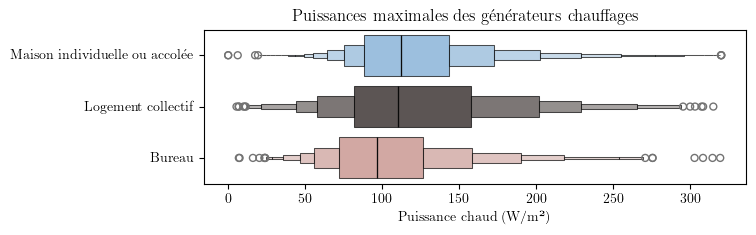

In [18]:
title = "Puissances maximales des générateurs chauffages"
from datetime import datetime
today = datetime.today()
from cmcrameri import cm
import matplotlib.pyplot as plt 
import simplstyles
import numpy as np
import seaborn as sns

plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "font.family": "serif",
    "font.serif": "Computer Modern",
})

cmap = cm.berlin



to_graph = to_graph.filter(
        # pl.col("mild_outliers") == False,
        pl.col("puissance_max_ch_surf_extreme_outliers") == False
    ).drop_nulls("usage_principal_1_txt")

order = [
    'Maison individuelle ou accolée','Logement collectif','Bureau',
    # 'Enseignement primaire','Enseignement secondaire (partie jour)'
    ]

palette = list(cmap(np.linspace(0.1,0.9,len(order))))

fig, ax = plt.subplots(figsize=(7,2))
sns.boxenplot(
    data=to_graph.to_pandas(),
    x="puissance_max_ch_surf",
    y="usage_principal_1_txt",
    order=order,
    hue="usage_principal_1_txt",
    hue_order=order,
    palette = palette,
    legend=False,
    ax=ax,
    alpha = 0.7
)

for j, usage in enumerate(order):
    subset = to_graph.filter(pl.col("usage_principal_1_txt") == usage)["puissance_max_ch_surf"]
    if len(subset) == 0:
        continue
    mean_val = subset.mean()
    median_val = subset.median()
    std_val = subset.std()
    y_max = 1.03 * subset.max()
    # ax.text(
    #     j, y_max,
    #     rf"N={len(subset)}\n \mu={mean_val:.1f}\nmed={median_val:.1f}\n\sigma={std_val:.1f}",
    #     ha='center', va='bottom',
    #     fontsize=9,
    #     color="#4c566a",
    #     linespacing=1.4
    # )


# ax.set_xticklabels(ax.get_xticklabels(),rotation = 45,ha="right")
ax.set_ylabel("")
ax.set_xlabel("Puissance chaud (W/m²)")
plt.suptitle(title)

plt.savefig(
    f"/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/{today.year}-{today.month}-{today.day}_{title}.pdf",
    dpi=300,
    bbox_inches = "tight"
    )

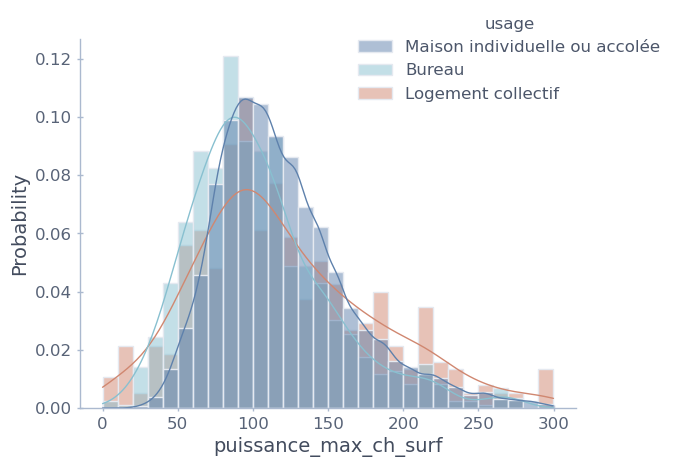

In [48]:
title = "Puissances maximales des générateurs chauffages"
from datetime import datetime
today = datetime.today()

import matplotlib.pyplot as plt 
import simplstyles
plt.style.use("nord-light")
import seaborn as sns

fig, ax = plt.subplots()
sns.histplot(data = to_graph.filter(
    pl.col("extreme_outliers")==False,
    # pl.col("puissance_max_ch")>0,
    pl.col("puissance_max_ch_surf")<300,
    ~pl.col("usage_principal_1_txt").str.contains("Enseignement")
    ),x = "puissance_max_ch_surf",hue= "usage_principal_1_txt",common_norm=False,stat = "probability",kde=True,binwidth = 10)

sns.move_legend(ax, loc="upper right",bbox_to_anchor = (1.2,1.1),title="usage")